# Leesmateriaal recommender

Deze notebook brengt de analyse, tekstbewerking en aanbevelingsalgoritmen samen. De codecellen zijn overgenomen uit de bestaande notebooks; de extra markdown licht de onderdelen en hun volgorde toe.



## 1. Analyse

In dit hoofdstuk worden de brongegevens verkend en opgeschoond voordat ze voor de aanbevelingen worden gebruikt.



### Leesmateriaal

We controleren en normaliseren de catalogusgegevens, bekijken datakwaliteit en onderzoeken de numerieke kenmerken van het leesmateriaal.



In [262]:
import pandas as pd
import numpy as np

In [263]:
df = pd.read_csv("./dataset/LeesmateriaalCSV.csv", sep=";")

In [264]:
# Controleren of Themas_boek en trefwoorden per rij identiek zijn
df["Themas_boek"] = (
    df["Themas_boek"]
    .astype("string")
    .fillna("")
    .str.replace(r"(?:https?://|www\.)\S+(?:\s+\[[^\]]+\])?", "", regex=True, case=False)
    .str.replace(r"\[[^\]]+\]", "", regex=True)
    .str.strip(" ,;")
)
themas_boek = df["Themas_boek"].astype("string").fillna("").map(
    lambda waarde: ";".join(woord.strip() for woord in waarde.split(";"))
)
trefwoorden = df["trefwoorden"].astype("string").fillna("").map(
    lambda waarde: ";".join(woord.strip() for woord in waarde.split(";"))
)
zelfde = themas_boek.eq(trefwoorden)
verschillen = df.loc[~zelfde, ["Titel", "Themas_boek", "trefwoorden"]]

print(f"Alle waarden identiek: {verschillen.empty}")
verschillen

Alle waarden identiek: False


,Titel,Themas_boek,trefwoorden
154,De wondere wereld van nachtvlinders,,[naturetoday.com]
155,Boeren geven de zwarte stern vleugels in de Ut...,,[naturetoday.com]
188,Zolang het tuin duurt 2,"zelfreflectie,doorzetten",zelfreflectie; doorzetten
201,De kleine kust,"jongeren,vriendschap",jongeren; vriendschap
231,Wat Joris niet wist,"doorzetten,liefde",doorzetten; liefde
242,Sleutel zonder kust,liefde/samenleving,liefde; samenleving
246,De brief van Jelle,geheimen|macht,geheimen; macht
254,Een foto voor Sem,"veerkracht,oorlog",veerkracht; oorlog
270,Het witte huis,reizen/oorlog,reizen; oorlog
282,Grens in de haven,"doorzetten,stalking",doorzetten; stalking


In [265]:
# Controleren of elk onderwerp in de trefwoorden voorkomt
onderwerpen = df["onderwerp"].astype("string").fillna("").str.strip().str.casefold()
trefwoorden = [
    [woord.strip().casefold() for woord in rij.split(";") if woord.strip()]
    for rij in df["trefwoorden"].astype("string").fillna("")
]
onderwerp_gevonden = pd.Series(
    [
        bool(onderwerp) and onderwerp in woorden
        for onderwerp, woorden in zip(onderwerpen, trefwoorden)
    ],
    index=df.index,
)
ontbreekt = df.loc[
    onderwerpen.ne("") & ~onderwerp_gevonden,
    ["Titel", "onderwerp", "trefwoorden"],
]
print(f"Alle onderwerpen staan in trefwoorden: {ontbreekt.empty}")
ontbreekt

Alle onderwerpen staan in trefwoorden: True


,Titel,onderwerp,trefwoorden


In [266]:
# Controleren of ingevulde genres_kopie al in genre staan
genre = df["genre"].astype("string").fillna("").str.strip().str.casefold()
genre_kopie = df["genre_kopie"].astype("string").fillna("").str.strip().str.casefold()
extra_genres = genre_kopie.ne("") & genre_kopie.ne(genre)
verschillen_genre = df.loc[extra_genres, ["Titel", "genre", "genre_kopie"]]

print(f"Alle ingevulde genres_kopie komen overeen met genre: {verschillen_genre.empty}")
verschillen_genre

Alle ingevulde genres_kopie komen overeen met genre: True


,Titel,genre,genre_kopie


In [267]:
#onnodige kolommen verwijderen
df = df.drop(columns=['Unnamed: 3', 'Themas_boek', 'materiaal_id', 'interne_batchcode', 'genre_kopie', 'woordenaantal_omschrijving', 'aandeel_lange_woorden_pct', 'aantal_zinnen', 'administratieve_prioriteit'])

In [268]:
# Genre uit Type materiaal verplaatsen als genre leeg is
mask = df["Type materiaal"].str.match(r"(?i)^boek\s*-", na=False)
genre = df.loc[mask, "Type materiaal"].str.split("-", n=1).str[1].str.strip()
missing_genre = df["genre"].isna()
df.loc[mask & missing_genre, "genre"] = genre.loc[mask & missing_genre]

In [269]:
#Type materiaal normaliseren
mask = df["Type materiaal"].str.match(r"(?i)^boek\s*-", na=False)
df.loc[mask, "Type materiaal"] = "boek"
df.loc[df["Type materiaal"] == "Boek", "Type materiaal"] = "boek"
df.loc[df["Type materiaal"] == "digitale krant", "Type materiaal"] = "krant (digitaal)"

In [270]:
#Taal normaliseren
df["taal"] = "NL"

In [271]:
#Doelgroep normaliseren
df.loc[df["doelgroep"] == "mbo", "doelgroep"] = "MBO"
df.loc[df["doelgroep"] == "mbo / nt2", "doelgroep"] = "MBO/NT2"

In [272]:
#Doelgroepen combineren
def combineer_doelgroepen(row):
    groepen = []

    for waarde in row.dropna():
        for groep in str(waarde).split("/"):
            groep = groep.strip()

            if groep != "" and groep not in groepen:
                groepen.append(groep)

    volgorde = {"MBO": 0, "NT2": 1}
    groepen.sort(key=lambda groep: volgorde.get(groep, 2))

    return "/".join(groepen)

df["doelgroep"] = df[["doelgroep", "doelgroep_extra"]].apply(
    combineer_doelgroepen, axis=1
)
df.loc[df["doelgroep"] == "", "doelgroep"] = np.nan

df = df.drop(["doelgroep_extra"], axis=1)

In [273]:
#onrealistische waarden in gem_woordlengte vervangen door NaN
df.loc[df["gem_woordlengte"] > 10, ["gem_woordlengte"]] = np.nan

In [274]:
#interessecluster normaliseren
df["interessecluster"] = df["interessecluster"].str.lower()

In [275]:
#onrealistische en onbekende jaartallen in publicatiejaar vervangen door 'onbekend'
df.loc[df["publicatiejaar"] == 'onbekend', ["publicatiejaar"]] = np.nan
df["publicatiejaar"] = df["publicatiejaar"].astype("Int64")
df.loc[df["publicatiejaar"] > 2026, ["publicatiejaar"]] = np.nan

In [276]:
#beschikbaar_formaat normaliseren
df["beschikbaar_formaat"] = df["beschikbaar_formaat"].str.lower()

In [277]:
#aantal_paginas normaliseren
df.loc[df["aantal_paginas"] < 1, "aantal_paginas"] = np.nan
df["aantal_paginas"] = df["aantal_paginas"].astype('Int64')

In [278]:
#geschatte_leestijd_min normaliseren
df.loc[df["geschatte_leestijd_min"] < 1, "geschatte_leestijd_min"] = np.nan

In [279]:
#Gegevensstatus opschonen en veranderen naar bruikbare data
df.loc[df["gegevensstatus"] == "Aangevuld (deels gesimuleerd)", ["gegevensstatus"]] = 'Beschikbaar'
df.loc[df["gegevensstatus"] == "gecontroleerd", ["gegevensstatus"]] = 'Binnenkort Terug Verwacht'
df.loc[df["gegevensstatus"] == "In behandeling", ["gegevensstatus"]] = 'Uitgeleend'
df.loc[df["gegevensstatus"].isna(), ["gegevensstatus"]] = 'Onbekend'

In [280]:
# Korte url-vermelding uit bron_url verwijderen
df["bron_url"] = df["bron_url"].str.replace(
    r"((?:https?://|www\.)\S+?)(?:\s*,?\s*\[[^\]]+\])+",
    r"\1",
    regex=True,
)

In [281]:
# Auteurs scheiden met een slash
df["Auteur"] = (
    df["Auteur"]
    .str.replace(r"\s+en\s+", ";", case=False, regex=True)
    .str.replace(r"\s*[,&]\s*", ";", regex=True)
    .str.replace(r"\s*/\s*", ";", regex=True)
    .str.strip()
)

In [282]:
df["trefwoorden"] = df["trefwoorden"].str.replace("; ", ";")

In [283]:
ag = df[df["aantal_paginas"].notna() & df["geschatte_leestijd_min"].notna()][["aantal_paginas", "geschatte_leestijd_min"]]

In [284]:
df[df["aantal_paginas"].isna() | df["geschatte_leestijd_min"].isna()]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,genre,onderwerp,trefwoorden,taal,aantal_paginas,...,gegevensstatus,gem_woordlengte,gem_zinslengte_woorden,leescomplexiteit_score,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,Gemiddelde beoordeling
5,De familie Blues,Yvonne Kroonenberg,Humoristische en herkenbare verhalen over fami...,boek,2F,fictie,familie,familie;humor,NL,<NA>,...,Beschikbaar,6.61,11.5,49.7,verhalen,Leeswereld,2013,papier,CAT-00006,3.0
6,De favoriete plekken van...,Floortje Dessing,Bekende Nederlanders vertellen over locaties d...,boek,2F,fictie,reizen,reizen;herinneringen,NL,162,...,Beschikbaar,6.90,10.0,50.2,vrije tijd,Educatief Media,2025,digitaal,CAT-00007,3.4
13,Een goede truc,Marjan Berk,Licht en toegankelijk verhaal waarin slim hand...,boek,2F,fictie,creativiteit,creativiteit;doorzetten,NL,<NA>,...,Beschikbaar,6.45,10.0,46.9,verhalen,Leeswereld,2023,pdf,CAT-00014,4.0
14,Floortje Dessing reisverhalen,Floortje Dessing,Verzameling reisverhalen waarin bijzondere bes...,boek,2F,NaN,reizen,reizen;cultuur,NL,157,...,Beschikbaar,6.55,10.0,51.7,vrije tijd,NaN,2013,online,CAT-00015,3.7
31,Sonny Boy (makkelijk),Annejet vd Zijl,Vereenvoudigde versie van het waargebeurde ver...,boek,2F,fictie,oorlog,oorlog;liefde,NL,<NA>,...,Beschikbaar,7.23,11.0,NaN,maatschappij,Educatief Media,2018,papier,CAT-00032,3.7
34,Twee Vrouwen,H. Mulisch,"Psychologische roman over liefde, verlangen en...",boek,3F+,fictie,liefde,liefde;verlies,NL,<NA>,...,Beschikbaar,6.55,10.0,47.2,verhalen,Educatief Media,2018,NaN,CAT-00035,3.6
55,Voor altijd jong (mijn leven met kanker),Jade Kops,Persoonlijk en aangrijpend verhaal over leven ...,boek,2F,fictie,ziekte,ziekte;veerkracht,NL,149,...,Uitgeleend,6.11,9.0,43.7,verhalen,Leeswereld,2025,NaN,CAT-00056,3.7
59,Op zoek naar mijn pad,Malala Yousafzai,"Inspirerend verhaal over identiteit, ambitie e...",boek,3F,fictie,identiteit,identiteit;ontwikkeling,NL,119,...,Beschikbaar,7.65,8.5,52.5,verhalen,Uitgeverij Noord,2023,digitaal,CAT-00060,3.6
60,Lord of the flies,Aimée de Jongh,Graphic novelbewerking van het beroemde verhaa...,boek,2F,fictie,macht,macht;groepsdruk,NL,<NA>,...,Beschikbaar,5.95,10.0,41.3,verhalen,NaN,2013,NaN,CAT-00061,3.0
63,De rechtsstaat moet je leren,Geert Corstens,"Toegankelijk boek over democratie, rechtspraak...",boek,3F,fictie,recht,recht;burgerschap,NL,<NA>,...,Binnenkort Terug Verwacht,6.16,9.5,46.3,maatschappij,NaN,1998,NaN,CAT-00064,3.5


In [285]:
gem_paginas_p_min = ag["aantal_paginas"].mean() / ag["geschatte_leestijd_min"].mean()
gem_min_p_p = ag["geschatte_leestijd_min"].mean() / ag["aantal_paginas"].mean()

df.loc[df["aantal_paginas"].isna() & df["geschatte_leestijd_min"].notna(), "aantal_paginas"] = (df["geschatte_leestijd_min"] * gem_paginas_p_min).round().astype("Int64")
df.loc[df["geschatte_leestijd_min"].isna() & df["aantal_paginas"].notna(), "geschatte_leestijd_min"] = df["aantal_paginas"] * gem_min_p_p

In [286]:
def create_new_row(df):
    kolommen = ["Korte omschrijving", "genre", "onderwerp", "trefwoorden", "Niveau", "uitgever", "beschikbaar_formaat", "Auteur"]
    delen = df[kolommen].fillna("").astype("string")
    df["Gecombineerd"] = delen.apply(
        lambda rij: "/".join(deel for deel in rij if deel.strip()),
        axis=1,
    )
    return df

In [287]:
df = create_new_row(df)

In [288]:
df.to_csv("./dataset/cleaned_Leesmateriaal.csv", index=False)

In [289]:
df.head()

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,genre,onderwerp,trefwoorden,taal,aantal_paginas,...,gem_woordlengte,gem_zinslengte_woorden,leescomplexiteit_score,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,Gemiddelde beoordeling,Gecombineerd
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,boek,3F,fictie,WOII,WOII;onderduik,NL,265,...,NaN,NaN,NaN,verhalen,Educatief Media,2025,pdf,CAT-00001,3.4,Dagboek van een Joods meisje dat tijdens de Tw...
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,boek,3F,fictie,spanning,spanning;stalking,NL,171,...,5.54,14.0,48.8,verhalen,Leeswereld,2005,digitaal,CAT-00002,2.5,Spannende thriller waarin een vrouw wordt geco...
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",boek,2F,fictie,liefde,liefde;relaties,NL,219,...,6.35,11.5,49.2,verhalen,NaN,2025,digitaal,CAT-00003,3.8,"Toegankelijk verhaal over liefde, relaties en ..."
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,boek,3F,fictie,ontmoeting,ontmoeting;verbondenheid,NL,288,...,7.35,11.5,55.3,verhalen,Uitgeverij Noord,2018,digitaal,CAT-00004,3.9,Bundel toegankelijke verhalen over verrassende...
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,boek,2F,fictie,geheimen,geheimen;schuld,NL,358,...,6.48,10.5,49.2,verhalen,Uitgeverij Noord,<NA>,online,CAT-00005,3.1,Verhaal waarin verborgen geheimen en persoonli...


In [290]:
# aantal unieke en missende waarden en datatypes
print("Aantal rijen en kolommen:", df.shape)
overzicht = pd.DataFrame({
    "Aantal unieke waarden": df.nunique(),
    "Aantal missende waarden": df.isna().sum(),
    "Datatype": df.dtypes,
    "Aantal dubbele waarden": df.apply(
        lambda kolom: kolom.dropna().duplicated().sum()
    )
})
 
display(overzicht)

Aantal rijen en kolommen: (283, 24)


,Aantal unieke waarden,Aantal missende waarden,Datatype,Aantal dubbele waarden
Titel,277,0,str,6
Auteur,231,7,str,45
Korte omschrijving,282,0,str,1
Type materiaal,7,0,str,276
Niveau,4,6,str,273
genre,5,15,str,263
onderwerp,47,181,str,55
trefwoorden,93,181,str,9
taal,1,0,str,282
aantal_paginas,170,0,Int64,113


#### Dimensionality reduction op de opgeschoonde data (PCA, t-SNE, UMAP)

**Wat gaan we doen?**
Elk boek heeft 5 cijfers (pagina's, leestijd, woordlengte, zinslengte en leescomplexiteit). Dat zijn te veel cijfers om in één plaatje te zetten. Met PCA, t-SNE en UMAP maken we er een plaatje van met maar 2 richtingen (links/rechts en omhoog/omlaag). Boeken die op elkaar lijken komen dan dicht bij elkaar te staan. Zo zien we of boeken van hetzelfde niveau op elkaar lijken.

**Wat gebeurt er in de code hieronder?**
1. **Features kiezen:** we kiezen de 5 getal-kolommen die we gebruiken om boeken te vergelijken.
2. **Label kiezen:** we kiezen `Niveau` (2F, 3F, 3F+) om de punten later mee te kleuren. Het label gebruiken de technieken zelf niet, het is alleen voor ons om te kijken of boeken van hetzelfde niveau bij elkaar komen te liggen.
3. **Kopie maken zonder lege waardes:** de technieken kunnen niet tegen lege vakjes. Daarom maken we een kopie (`df_analyse`) met alleen de boeken waar alle 5 de cijfers zijn ingevuld. De originele tabel `df` blijft zoals hij was, zodat we de lege waardes later nog kunnen invullen.
4. **Schalen:** leestijd is een groot getal (honderden) en woordlengte een klein getal (rond 6). Zonder schalen telt het grote getal te zwaar mee. Met `StandardScaler` brengen we alle kolommen op dezelfde schaal.
5. **Plotfunctie:** `plot_2d` is een hulpfunctie die een plaatje maakt waarin elk punt een boek is, gekleurd per niveau. Die gebruiken we straks bij alle drie de technieken.

De code print ook hoeveel boeken er meedoen en hoeveel er zijn weggelaten door lege waardes.

In [291]:
# --- Features, labels en schalen ---
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1) Welke numerieke kolommen gebruiken we als features, en waarop kleuren we de punten?
features = [
    "aantal_paginas",
    "geschatte_leestijd_min",
    "gem_woordlengte",
    "gem_zinslengte_woorden",
    "leescomplexiteit_score",
]
label_kolom = "Niveau"

# 2) Kopie met alleen volledige rijen (df zelf blijft ongemoeid)
# LET OP: na feature engineering vervang je hier df door de ingevulde dataframe
# en laat je (indien alles is ingevuld) .dropna() alleen nog voor het label staan.
df_analyse = df[features + [label_kolom]].dropna().copy()
df_analyse[features] = df_analyse[features].astype(float)  # Int64 -> float

X = df_analyse[features].to_numpy()
y = df_analyse[label_kolom].to_numpy()   # labels (2F, 2F-3F, 3F, 3F+) om punten te kleuren

# 3) Schalen (gemiddelde 0, std 1): leestijd loopt in honderden, woordlengte rond 6
X_scaled = StandardScaler().fit_transform(X)

print(f"Rijen in df: {len(df)} | rijen in analyse: {len(df_analyse)} "
      f"({len(df) - len(df_analyse)} weggelaten door lege waardes)")
print("X_scaled shape:", X_scaled.shape)
print(df_analyse[label_kolom].value_counts())


def plot_2d(X_2d, titel, xlabel, ylabel):
    """Scatterplot per label (Niveau) met legenda."""
    plt.figure(figsize=(7, 5))
    for label in sorted(np.unique(y)):
        m = y == label
        plt.scatter(X_2d[m, 0], X_2d[m, 1], s=40, alpha=0.8, label=label)
    plt.title(titel)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(title=label_kolom)
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.show()

Rijen in df: 283 | rijen in analyse: 238 (45 weggelaten door lege waardes)
X_scaled shape: (238, 5)
Niveau
2F       120
3F        77
3F+       25
2F-3F     16
Name: count, dtype: int64


##### PCA

**Wat doet PCA?**
PCA zoekt de "beste hoek" om naar je boeken te kijken. Het maakt van de 5 cijfers per boek 2 nieuwe cijfers (5D -> 2D), zodat je een plaatje kunt maken. Het kiest die 2 nieuwe cijfers zo, dat je zoveel mogelijk van de verschillen tussen de boeken blijft zien. Het is net als een foto van een 3D-voorwerp: je kiest de hoek waarop je het meeste ziet.

**Wat gebeurt er in de code hieronder?**
1. **PCA uitvoeren:** we vragen om 2 nieuwe assen, PC1 (links/rechts) en PC2 (omhoog/omlaag). PC1 laat de meeste verschillen tussen de boeken zien, PC2 de tweede meeste.
2. **Verklaarde variantie:** de code print hoeveel procent van alle verschillen elke as laat zien. Zijn die twee getallen samen hoog, dan is het plaatje betrouwbaar. Het stuk dat ontbreekt tot 100% is informatie die we kwijt zijn door van 5 naar 2 te gaan.
3. **Loadings:** een tabel die laat zien hoe PC1 en PC2 zijn opgebouwd uit de 5 oorspronkelijke kolommen. Een getal ver van 0 betekent dat die kolom zwaar meetelt voor die as. Een plus en een min betekenen dat de kolommen elkaars tegenpool zijn (de ene hoog, de andere laag). Zo kun je uitleggen wat een as eigenlijk betekent.
4. **Plaatje:** elk punt is een boek, gekleurd per niveau. Punten die dicht bij elkaar liggen zijn boeken die op elkaar lijken.

**Let op:** PCA is de enige van de drie technieken waarbij de assen echt iets betekenen. Bij t-SNE en UMAP zijn de assen alleen een plek op het plaatje.

Verklaarde variantie ratio (per component): [0.45483475 0.30838683]
Totaal verklaarde variantie: 0.7632215724239584


,PC1,PC2
aantal_paginas,0.50,0.38
geschatte_leestijd_min,0.45,0.40
gem_woordlengte,-0.50,0.50
gem_zinslengte_woorden,0.47,0.15
leescomplexiteit_score,-0.29,0.65


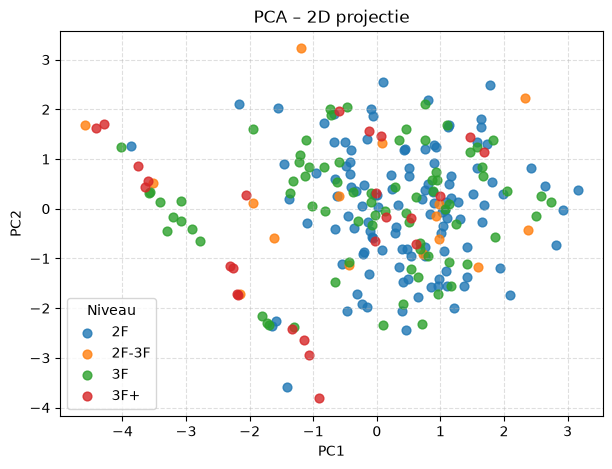

In [292]:
# --- PCA: lineaire reductie naar 2D ---
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Verklaarde variantie ratio (per component):", pca.explained_variance_ratio_)
print("Totaal verklaarde variantie:", pca.explained_variance_ratio_.sum())

# Loadings: welke features wegen zwaar mee in PC1 en PC2?
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
display(loadings.round(2))

plot_2d(X_pca, "PCA – 2D projectie", "PC1", "PC2")

##### t-SNE

**Wat doet t-SNE?**
t-SNE kijkt bij elk boek wie er in de buurt zit: welke boeken lijken het meest op dit boek? Daarna maakt het een plaatje waarin die buren ook echt naast elkaar liggen. Het is net als een klas die in groepjes gaat zitten: wie op elkaar lijkt, zit bij elkaar. Daardoor is t-SNE goed in het zichtbaar maken van groepjes (clusters).

**Wat gebeurt er in de code hieronder?**
1. **t-SNE uitvoeren:** we vragen om 2 nieuwe assen, zodat we een plaatje kunnen maken.
2. **Perplexity = 30:** dit getal bepaalt met hoeveel buren elk boek rekening houdt. Een laag getal kijkt naar heel kleine groepjes, een hoog getal naar grotere groepen. 30 is een gangbare beginwaarde.
3. **random_state = 42:** t-SNE gebruikt een beetje toeval. Met dit getal krijg je elke keer hetzelfde plaatje als je de cel opnieuw draait.
4. **Plaatje:** elk punt is een boek, gekleurd per niveau.

**Hoe lees je het plaatje?**
- Punten die dicht bij elkaar liggen, zijn boeken die op elkaar lijken. Dat mag je gebruiken.
- Een los groepje betekent dat die boeken op elkaar lijken en anders zijn dan de rest.
- De assen betekenen niets, het zijn alleen plekken op het plaatje. Ze hebben dus geen echte naam, daarom heten ze "Dim 1" en "Dim 2".
- De afstand tussen twee groepjes zegt niets. Een groepje dat ver weg ligt, is dus niet per se "anderder" dan een groepje dat dichtbij ligt.
- Er is geen "verklaarde variantie" zoals bij PCA, want t-SNE meet geen verschillen op één as.

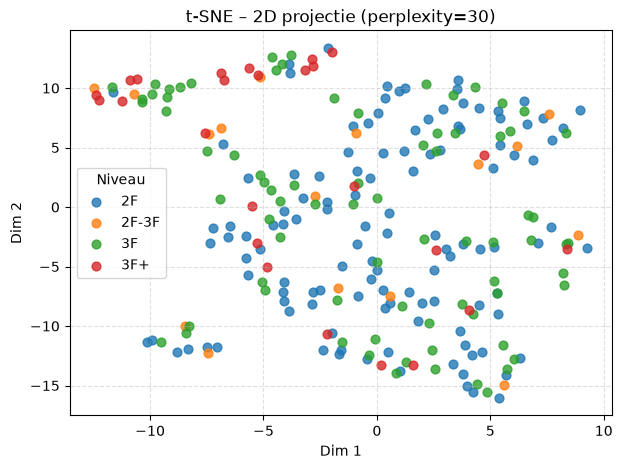

In [293]:
# --- t-SNE: focust op lokale structuur / clustervorming ---
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plot_2d(X_tsne, "t-SNE – 2D projectie (perplexity=30)", "Dim 1", "Dim 2")

##### UMAP

**Wat doet UMAP?**
UMAP werkt een beetje zoals t-SNE: het kijkt bij elk boek wie er in de buurt zit en zet die buren in het plaatje bij elkaar. Het verschil is dat UMAP ook een beetje let op het grote geheel. Groepjes die in het echt dicht bij elkaar zitten, komen daardoor vaker ook op het plaatje dicht bij elkaar te liggen. UMAP is ook meestal sneller dan t-SNE.

**Wat gebeurt er in de code hieronder?**
1. **UMAP uitvoeren:** we vragen om 2 nieuwe assen, zodat we een plaatje kunnen maken.
2. **n_neighbors = 15:** met hoeveel buren houdt elk boek rekening? Een laag getal kijkt naar kleine groepjes, een hoog getal naar grotere groepen. 15 is een gangbare beginwaarde.
3. **min_dist = 0.1:** hoe dicht mogen punten in een groepje op elkaar zitten? Een laag getal geeft strakke, dichte groepjes. Een hoger getal spreidt de punten meer uit.
4. **random_state = 42:** UMAP gebruikt een beetje toeval. Met dit getal krijg je elke keer hetzelfde plaatje.
5. **Plaatje:** elk punt is een boek, gekleurd per niveau.

**Hoe lees je het plaatje?**
- Punten die dicht bij elkaar liggen, zijn boeken die op elkaar lijken.
- Een los groepje betekent dat die boeken op elkaar lijken en anders zijn dan de rest.
- De assen betekenen niets, net als bij t-SNE. Daarom heten ze "Dim 1" en "Dim 2".
- De afstand tussen groepjes zegt bij UMAP iets meer dan bij t-SNE, maar lees er niet te veel in.

**Eenmalig nodig:** staat UMAP nog niet op je computer? Verwijder het hekje voor `!pip install umap-learn`, draai die regel één keer en zet het hekje weer terug. Krijg je een waarschuwing (`UserWarning`) over `n_jobs`? Die is onschuldig: hij komt doordat we `random_state` hebben ingesteld.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


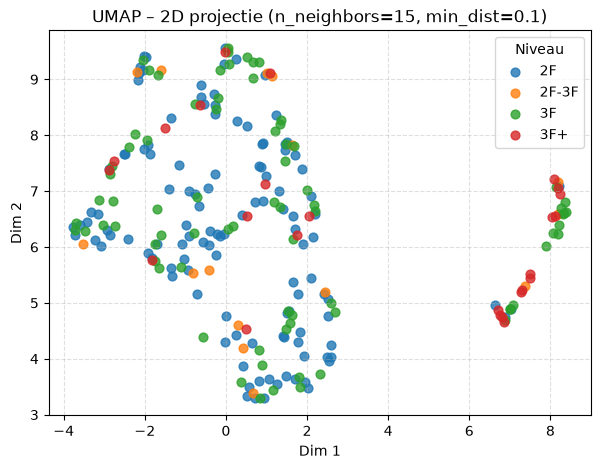

In [294]:
# --- UMAP: snel en behoudt lokale + deels globale structuur ---
import umap

umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

plot_2d(X_umap, "UMAP – 2D projectie (n_neighbors=15, min_dist=0.1)", "Dim 1", "Dim 2")

### Interacties

De interactiegegevens worden ingelezen, leespercentages worden genormaliseerd en de kwaliteit van de gegevens wordt samengevat.



In [295]:
import pandas as pd
import numpy as np

In [296]:
dfInter = pd.read_csv("./dataset/InteractiesCSV.csv", sep=";")

In [297]:
dfInter["leespercentage"] = dfInter["leespercentage"].str.removesuffix("%").astype(np.int64)

In [298]:
dfInter

,interactie_id,student_id,cataloguscode,interactietype,beoordeling,leespercentage,leestijd_min,datum
0,I00001,S001,CAT-00223,opgeslagen,4.0,88,305,2026-01-17
1,I00002,S001,CAT-00253,bekeken,3.0,42,93,2026-08-24
2,I00003,S001,CAT-00055,opgeslagen,4.0,84,299,2026-10-14
3,I00004,S001,CAT-00266,gelezen,4.0,82,235,2026-05-04
4,I00005,S001,CAT-00262,niet_afgemaakt,2.0,14,2,2026-02-19
...,...,...,...,...,...,...,...,...
1995,I01996,S100,CAT-00030,gelezen,4.0,99,261,2026-04-30
1996,I01997,S100,CAT-00250,niet_afgemaakt,3.0,60,98,2026-07-16
1997,I01998,S100,CAT-00066,gelezen,4.0,96,698,2026-09-03
1998,I01999,S100,CAT-00009,bekeken,NaN,57,318,2026-01-08


In [299]:
dfInter.to_csv("./dataset/cleaned_Interacties.csv", index=False)

In [300]:
# aantal unieke en missende waarden en datatypes
print("Aantal rijen en kolommen:", dfInter.shape)
overzicht = pd.DataFrame({
    "Aantal unieke waarden": dfInter.nunique(),
    "Aantal missende waarden": dfInter.isna().sum(),
    "Datatype": dfInter.dtypes,
    "Aantal dubbele waarden": dfInter.apply(
        lambda kolom: kolom.dropna().duplicated().sum()
    )
})
 
display(overzicht)

Aantal rijen en kolommen: (2000, 8)


,Aantal unieke waarden,Aantal missende waarden,Datatype,Aantal dubbele waarden
interactie_id,2000,0,str,0
student_id,100,0,str,1900
cataloguscode,276,0,str,1724
interactietype,6,0,str,1994
beoordeling,5,373,float64,1622
leespercentage,101,0,int64,1899
leestijd_min,560,0,int64,1440
datum,288,0,str,1712


### Student

De studentgegevens worden ingelezen, taalvoorkeuren worden gestandaardiseerd en de datakwaliteit wordt bekeken.



In [301]:
dfStud = pd.read_csv("./dataset/StudentCSV.csv", sep=";")

In [302]:
dfStud.head()

,student_id,leeftijdscategorie,leesniveau,taalniveau,interesses,voorkeur_materiaaltype,voorkeur_genre,max_leestijd_min,voorkeur_taal
0,S001,22+,2F,C1,"kunstmatige intelligentie, relaties",Boek,informatief,60,Nederlands
1,S002,19-21,2F,B1,"reizen, persoonlijke ontwikkeling",Boek,informatief,60,Nederlands
2,S003,16-18,2F,C1,"technologie, humor, sport",gemengd,informatief,15,Nederlands
3,S004,16-18,2F,B2,"vriendschap, natuur, klimaat",online artikel,poëzie,30,Nederlands
4,S005,19-21,2F,B2,"kunstmatige intelligentie, muziek",online artikel,geen voorkeur,120,Nederlands


In [303]:
dfStud.loc[dfStud["voorkeur_taal"] == "Nederlands", "voorkeur_taal"] = "NL"
dfStud.loc[dfStud["voorkeur_taal"] == "Engels", "voorkeur_taal"] = "EN"

In [304]:
dfStud.to_csv("./dataset/cleaned_Student.csv", index=False)

In [305]:
dfStud.head()

,student_id,leeftijdscategorie,leesniveau,taalniveau,interesses,voorkeur_materiaaltype,voorkeur_genre,max_leestijd_min,voorkeur_taal
0,S001,22+,2F,C1,"kunstmatige intelligentie, relaties",Boek,informatief,60,NL
1,S002,19-21,2F,B1,"reizen, persoonlijke ontwikkeling",Boek,informatief,60,NL
2,S003,16-18,2F,C1,"technologie, humor, sport",gemengd,informatief,15,NL
3,S004,16-18,2F,B2,"vriendschap, natuur, klimaat",online artikel,poëzie,30,NL
4,S005,19-21,2F,B2,"kunstmatige intelligentie, muziek",online artikel,geen voorkeur,120,NL


In [306]:
# aantal unieke en missende waarden en datatypes
print("Aantal rijen en kolommen:", dfStud.shape)
overzicht = pd.DataFrame({
    "Aantal unieke waarden": dfStud.nunique(),
    "Aantal missende waarden": dfStud.isna().sum(),
    "Datatype": dfStud.dtypes,
    "Aantal dubbele waarden": dfStud.apply(
        lambda kolom: kolom.dropna().duplicated().sum()
    )
})
 
display(overzicht)

Aantal rijen en kolommen: (100, 9)


,Aantal unieke waarden,Aantal missende waarden,Datatype,Aantal dubbele waarden
student_id,100,0,str,0
leeftijdscategorie,3,0,str,97
leesniveau,3,0,str,97
taalniveau,4,0,str,96
interesses,99,0,str,1
voorkeur_materiaaltype,3,0,str,97
voorkeur_genre,4,0,str,96
max_leestijd_min,7,0,int64,93
voorkeur_taal,2,0,str,98


## 2. NLP-tekstbewerking

In deze stap worden de catalogusteksten voorbereid voor tekstuele vergelijking.



### Leesmateriaal

De beschrijvende velden worden samengevoegd. Daarna worden tekst en leestekens opgeschoond, stopwoorden verwijderd en woorden met het Nederlandse spaCy-model gelemmatiseerd. De verwerkte tekst wordt aan de catalogus toegevoegd.



In [307]:
#!pip install nltk

In [308]:
#%pip install spacy

In [309]:
#import sys
#!{sys.executable} -m spacy download nl_core_news_lg

In [310]:
import pandas as pd
import nltk
import numpy as np

In [311]:
df = pd.read_csv("./dataset/cleaned_Leesmateriaal.csv")
SamenKolom = df["Gecombineerd"]

In [312]:
SamenKolom = SamenKolom.str.lower()

In [313]:
#cijfers met spatie ervoor en erna verwijderen
SamenKolom = SamenKolom.str.replace(r'(?<=\s)\d+(?=\s)', '', regex=True)

In [314]:
#puntkomma's en schuine strepen vervangen door spaties
SamenKolom = SamenKolom.str.replace(';', ' ')
SamenKolom = SamenKolom.str.replace('/', ' ')

In [315]:
#alle overige leestekens verwijderen
SamenKolom = SamenKolom.str.replace(r'[^\w\s]', '', regex=True)

In [316]:
#dubbele spaties verwijderen
SamenKolom = SamenKolom.str.replace(r'\s+', ' ', regex=True)
SamenKolom = SamenKolom.str.strip()

In [317]:
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('dutch'))

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/vinvalentino/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [318]:
#functie om stopwoorden te verwijderen
def verwijder_stopwoorden(zin):
    woorden = zin.split()
    nieuwe_woorden = []

    for woord in woorden:
        if woord.lower() not in stop_words:
            nieuwe_woorden.append(woord)

    return ' '.join(nieuwe_woorden)

SamenKolom = SamenKolom.apply(verwijder_stopwoorden)

In [319]:
#functie om woorden te stammen (SnowballStemmer voor Nederlands)
# from nltk.stem.snowball import SnowballStemmer

# stemmer = SnowballStemmer("dutch")

# def stam_tekst(zin):
#     woorden = zin.split()
#     gestamde_woorden = []

#     for woord in woorden:
#         gestamde_woorden.append(stemmer.stem(woord))

#     return " ".join(gestamde_woorden)

# SamenKolom = SamenKolom.apply(stam_tekst)

In [320]:
#functie om woorden te lemmatiseren (Spacy voor Nederlands)
import spacy

nlp = spacy.load("nl_core_news_lg")

def lemmatiseer(zin):
    woorden = nlp(zin)
    nieuwe_woorden = []

    for woord in woorden:
        if not woord.is_punct:
            nieuwe_woorden.append(woord.lemma_)

    return " ".join(nieuwe_woorden)

SamenKolom = SamenKolom.apply(lemmatiseer)

In [321]:
df["nlp"] = SamenKolom

In [322]:
df.to_csv("./dataset/cleaned_Leesmateriaal.csv", index=False)

### Interacties

Interactietype, leespercentage en beoordeling worden gecombineerd tot een interactiescore. Daarna wordt een student-itemmatrix opgebouwd voor de collaboratieve aanbevelingen.



In [323]:
intdf = pd.read_csv("./dataset/cleaned_Interacties.csv")

In [324]:

# aantal unieke en missende waarden en datatypes
print("Aantal rijen en kolommen:", intdf.shape)
overzicht = pd.DataFrame({
    "Aantal unieke waarden": intdf.nunique(),
    "Aantal missende waarden": intdf.isna().sum(),
    "Datatype": intdf.dtypes,
    "Aantal dubbele waarden": intdf.apply(
        lambda kolom: kolom.dropna().duplicated().sum()
    )
})
 
display(overzicht)

Aantal rijen en kolommen: (2000, 8)


,Aantal unieke waarden,Aantal missende waarden,Datatype,Aantal dubbele waarden
interactie_id,2000,0,str,0
student_id,100,0,str,1900
cataloguscode,276,0,str,1724
interactietype,6,0,str,1994
beoordeling,5,373,float64,1622
leespercentage,101,0,int64,1899
leestijd_min,560,0,int64,1440
datum,288,0,str,1712


In [325]:
intdf[1995:2000]

,interactie_id,student_id,cataloguscode,interactietype,beoordeling,leespercentage,leestijd_min,datum
1995,I01996,S100,CAT-00030,gelezen,4.0,99,261,2026-04-30
1996,I01997,S100,CAT-00250,niet_afgemaakt,3.0,60,98,2026-07-16
1997,I01998,S100,CAT-00066,gelezen,4.0,96,698,2026-09-03
1998,I01999,S100,CAT-00009,bekeken,NaN,57,318,2026-01-08
1999,I02000,S100,CAT-00143,bekeken,3.0,37,3,2026-10-15


In [326]:
intdf["interactietype"].unique().tolist()

['opgeslagen', 'bekeken', 'gelezen', 'niet_afgemaakt', 'geliket', 'afgewezen']

In [327]:
inttype = intdf["interactietype"]

In [328]:
inttype.unique().tolist()

['opgeslagen', 'bekeken', 'gelezen', 'niet_afgemaakt', 'geliket', 'afgewezen']

In [329]:
#interactietypes waardes geven van 1 tot 5
inttype.loc[inttype == "geliket"] = "5"
inttype.loc[inttype == "opgeslagen"] = "4"
inttype.loc[inttype == "gelezen"] = "3"
inttype.loc[inttype == "bekeken"] = "2"
inttype.loc[inttype == "niet_afgemaakt"] = "1"
inttype.loc[inttype == "afgewezen"] = "1"
inttype = inttype.astype(float)

In [330]:
leesprc = intdf["leespercentage"]

In [331]:
#leespercentage waardes geven van 1 tot 5
# leesprc = leesprc.apply(lambda x: round(x / 20))
# leesprc = leesprc.astype(float)

leesprc = np.ceil(leesprc / 20).clip(1, 5).astype(float)

In [332]:
leesprc.unique().tolist()

[5.0, 3.0, 1.0, 4.0, 2.0]

In [333]:
#interacties score berekenen, lege waardes worden niet meegenomen
scores = pd.DataFrame({
    "leesprc": leesprc,
    "inttype": inttype,
    "beoordeling": intdf["beoordeling"],
}, index=intdf.index)

weights = pd.Series({
    "leesprc": 0.15,
    "inttype": 0.35,
    "beoordeling": 0.50,
})

weighted_sum = scores.mul(weights, axis="columns").sum(axis=1, min_count=1)
available_weight = scores.notna().mul(weights, axis="columns").sum(axis=1)

intscore = weighted_sum / available_weight

In [334]:
intscore

0       4.15
1       2.65
2       4.15
3       3.80
4       1.50
        ... 
1995    3.80
1996    2.30
1997    3.80
1998    2.30
1999    2.50
Length: 2000, dtype: float64

In [335]:
intdf["intscore"] = intscore

In [336]:
intdf.head()

,interactie_id,student_id,cataloguscode,interactietype,beoordeling,leespercentage,leestijd_min,datum,intscore
0,I00001,S001,CAT-00223,opgeslagen,4.0,88,305,2026-01-17,4.15
1,I00002,S001,CAT-00253,bekeken,3.0,42,93,2026-08-24,2.65
2,I00003,S001,CAT-00055,opgeslagen,4.0,84,299,2026-10-14,4.15
3,I00004,S001,CAT-00266,gelezen,4.0,82,235,2026-05-04,3.80
4,I00005,S001,CAT-00262,niet_afgemaakt,2.0,14,2,2026-02-19,1.50


In [337]:
intdf.to_csv("./dataset/cleaned_Interacties.csv", index=False)

In [338]:
intdf["intscore"] = intscore

student_item_matrix = intdf.pivot_table(
    index="student_id",
    columns="cataloguscode",
    values="intscore",
    aggfunc="mean"
)

student_item_matrix.head()

cataloguscode,CAT-00001,CAT-00002,CAT-00003,CAT-00004,CAT-00005,CAT-00006,CAT-00007,CAT-00008,CAT-00009,CAT-00010,...,CAT-00274,CAT-00275,CAT-00276,CAT-00277,CAT-00278,CAT-00279,CAT-00280,CAT-00281,CAT-00282,CAT-00283
student_id,,,,,,,,,,,,,,,,,,,,,
S001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.65,NaN,NaN
S002,NaN,NaN,NaN,NaN,4.15,NaN,NaN,NaN,2.3,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S004,1.65,NaN,NaN,NaN,NaN,NaN,2.8,NaN,2.5,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN
S005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [339]:
student_item_matrix.to_csv("./matrix/student_item_matrix.csv", index=True)

## 3. Algoritme

De aanbevelingen worden op twee manieren opgebouwd: op basis van vergelijkbare studenten en op basis van de inhoud van leesmaterialen.



### Collaboratief

Collaborative filtering vergelijkt scorepatronen tussen studenten. De volgende cellen tonen vergelijkbare studenten, genereren aanbevelingen en evalueren de prestaties op testdata.



In [340]:
# Vergelijk de scorepatronen van alle studenten op materialen.
# .T draait de matrix om, zodat corr() de studenten met elkaar vergelijkt.
# min_periods=3 vereist minstens 3 materialen met scores van beide studenten.
student_similarity = student_item_matrix.T.corr(min_periods=3)

# Maak een matrix waarin 1 betekent dat een score bekend is en 0 dat die ontbreekt.
# De matrixvermenigvuldiging telt per studentenpaar hoeveel materialen zij delen.
overlap = (
    student_item_matrix.notna().astype(int)
    @ student_item_matrix.notna().astype(int).T
)

# Kies voor dit voorbeeld de eerste student uit de matrix.
# De volgende cel gebruikt expliciet S001.
student_id = student_similarity.index[0]
# Pak de correlaties van deze student met alle andere studenten.
neighbors = (
    student_similarity[student_id]
    # Verwijder de student zelf: die is altijd volledig gelijk aan zichzelf.
    .drop(index=student_id)
    # Verwijder studenten waarvoor geen correlatie berekend kon worden.
    .dropna()
    # Zet de hoogste correlaties bovenaan.
    .sort_values(ascending=False)
    # Bewaar de 5 hoogste correlaties (die kunnen ook negatief zijn).
    .head(5)
)
# Toon de meest vergelijkbare studenten en het aantal gedeelde materialen
# Toon de gekozen student en de correlaties met diens vergelijkbare studenten.
print("Student:", student_id)
print("Vergelijkbare studenten:")
print(neighbors)
# Toon hoeveel materialen deze studenten met de gekozen student gemeen hebben.
print("Gedeelde materialen:")
print(overlap.loc[student_id, neighbors.index])

Student: S001
Vergelijkbare studenten:
student_id
S051    0.967476
S002    0.923159
S038    0.919960
S014    0.899513
S006    0.815210
Name: S001, dtype: float64
Gedeelde materialen:
student_id
S051    3
S002    3
S038    4
S014    3
S006    3
Name: S001, dtype: int64


In [341]:
# Kies de student voor wie we aanbevelingen willen maken.
target = "S001"

# Haal de correlaties van deze student met anderen op.
# Verwijder de student zelf en correlaties die niet berekend konden worden.
neighbors = student_similarity[target].drop(target).dropna()
# Houd alleen positief vergelijkbare studenten over en kies de 5 sterkste buren.
neighbors = neighbors[neighbors > 0].nlargest(5)

# Haal de scores op die deze buren aan alle materialen hebben gegeven.
neighbor_scores = student_item_matrix.loc[neighbors.index]

# Vermenigvuldig elke score met de gelijkenis van de buur en tel dit per materiaal op.
# min_count=1 zorgt dat een materiaal zonder scores NaN blijft in plaats van 0.
weighted_sum = neighbor_scores.mul(neighbors, axis=0).sum(axis=0, min_count=1)
# Tel per materiaal de gelijkenissen op van de buren die het hebben beoordeeld.
weight_sum = neighbor_scores.notna().mul(neighbors, axis=0).sum(axis=0)
# Deel de gewogen scoresom door de gebruikte gewichten voor een voorspelde score.
predicted_scores = weighted_sum / weight_sum

# Tel hoeveel buren voor elk materiaal een score hebben gegeven.
support = neighbor_scores.notna().sum(axis=0)
# Bepaal welke materialen de gekozen student nog niet heeft beoordeeld.
unseen = student_item_matrix.loc[target].isna()

# Houd alleen onbekende materialen over die door minstens 2 buren zijn beoordeeld.
# Sorteer op voorspelde score en selecteer de 10 hoogste aanbevelingen.
recommendations = (
    predicted_scores[unseen & (support >= 2)]
    .sort_values(ascending=False)
    .head(10)
)

# Toon de aanbevolen cataloguscodes met hun voorspelde scores.
print(recommendations)

cataloguscode
CAT-00156    4.429498
CAT-00181    3.829102
CAT-00264    3.731406
CAT-00128    3.726758
CAT-00034    3.269816
CAT-00030    3.210524
CAT-00195    2.999572
CAT-00079    2.985703
CAT-00202    2.890270
CAT-00157    2.867071
dtype: float64


In [342]:
# Eén score per student-materiaalcombinatie; voorkom dat dezelfde combinatie
# zowel in train als test terechtkomt.
pairs = (
    intdf.groupby(["student_id", "cataloguscode"], as_index=False)["intscore"]
    .mean()
)

# Houd per student willekeurig 20% van de interacties achter.
test = pairs.groupby("student_id", group_keys=False).sample(
    frac=0.2, random_state=42
)
train = pairs.drop(index=test.index)

# Bouw de matrix opnieuw op met uitsluitend train-data.
students = pairs["student_id"].unique()
items = pairs["cataloguscode"].unique()

train_matrix = (
    train.pivot(index="student_id", columns="cataloguscode", values="intscore")
    .reindex(index=students, columns=items)
)

# Bereken opnieuw de student-similarity op train-data.
similarity = train_matrix.T.corr(min_periods=3)


def recommend(user_id, k=3):
    neighbors = similarity.loc[user_id].drop(index=user_id).dropna()
    neighbors = neighbors[neighbors > 0].nlargest(k)

    if neighbors.empty:
        return []

    neighbor_scores = train_matrix.loc[neighbors.index]
    weighted_sum = neighbor_scores.mul(neighbors, axis=0).sum(axis=0, min_count=1)
    weight_sum = neighbor_scores.notna().mul(neighbors, axis=0).sum(axis=0)
    predicted = weighted_sum / weight_sum

    support = neighbor_scores.notna().sum(axis=0)
    unseen = train_matrix.loc[user_id].isna()

    return predicted[unseen & (support >= 2)].nlargest(k).index.tolist()


# Definieer vooraf wat je als een relevante interactie ziet.
# 4.0 is een startpunt op jouw intscore-schaal; pas dit aan als dat beter
# aansluit bij jouw definitie van "interessant".
relevant_items = (
    test.loc[test["intscore"] >= 4.0]
    .groupby("student_id")["cataloguscode"]
    .apply(set)
)

results = []
k = 5

for user_id, relevant in relevant_items.items():
    recs = recommend(user_id, k=k)
    hits = [item in relevant for item in recs]

    precision_at_3 = sum(hits) / k

    dcg = sum(
        1 / np.log2(rank + 1)
        for rank, is_relevant in enumerate(hits, start=1)
        if is_relevant
    )
    ideal_hits = min(k, len(relevant))
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    ndcg_at_3 = dcg / idcg if idcg else 0

    results.append({
        "student_id": user_id,
        "Precision@3": precision_at_3,
        "NDCG@3": ndcg_at_3,
    })

scores = pd.DataFrame(results)
print(scores[["Precision@3", "NDCG@3"]].mean())

Precision@3    0.026087
NDCG@3         0.062380
dtype: float64


In [343]:
import pandas as pd
import numpy as np

In [344]:

# Instellingen om te tweaken
# Aantal aanbevelingen; bepaalt ook de K in Precision@K en NDCG@K.
TOP_K = 3
# Maximumaantal meest vergelijkbare studenten dat voor voorspellingen wordt gebruikt.
N_NEIGHBORS = 5
# Minimumaantal gedeelde materialen waarop een studentcorrelatie wordt berekend.
MIN_COMMON_ITEMS = 2
# Minimumaantal gekozen buren dat een materiaal moet hebben beoordeeld.
MIN_ITEM_SUPPORT = 1
# Vanaf deze intscore telt een achtergehouden materiaal als relevant.
RELEVANCE_THRESHOLD = 4
# Deel van de interactieparen per student dat als testdata wordt achtergehouden.
TEST_FRACTION = 0.3
# Verschillende seeds voor herhaalde, reproduceerbare train/test-splits.
# Gebruik dezelfde lijst wanneer je verschillende instellingen vergelijkt.
RANDOM_STATES = [11, 21, 31, 41, 51, 61, 71, 81, 91, 1]
# True gebruikt alleen positief gecorreleerde buren; False laat ook andere correlaties toe.
ONLY_POSITIVE_NEIGHBORS = True
# Kies componenten voor de interactiescore door regels toe te voegen of weg te laten.
# De gewichten geven het relatieve belang; ze worden automatisch genormaliseerd.
SCORE_WEIGHTS = {
    # 'leesprc': 0.15,      # Afgeleid van leespercentage (omgezet naar een 0-5-schaal).
    # 'inttype': 0.25,      # Afgeleid van interactietype via eval_type_scores hieronder.
    'beoordeling': 0.75,  # De beoordeling uit de interactiedata.
}

# Lees de opgeschoonde data en bereken de interactiescore, onafhankelijk van de baselinecellen.
eval_raw = pd.read_csv('./dataset/cleaned_Interacties.csv')

eval_type_scores = {
    'geliket': 5.0,
    'opgeslagen': 4.0,
    'gelezen': 3.0,
    'bekeken': 2.0,
    'niet_afgemaakt': 1.0,
    'afgewezen': 1.0,
}
eval_unknown_types = (
    set(eval_raw['interactietype'].dropna().unique()) - set(eval_type_scores)
)
if eval_unknown_types:
    raise ValueError('Onbekende interactietypes: {}'.format(sorted(eval_unknown_types)))

eval_all_inputs = pd.DataFrame({
    'leesprc': (eval_raw['leespercentage'] / 20).round(),
    'inttype': eval_raw['interactietype'].map(eval_type_scores),
    'beoordeling': pd.to_numeric(eval_raw['beoordeling'], errors='coerce'),
})
if not SCORE_WEIGHTS:
    raise ValueError('SCORE_WEIGHTS moet minstens één scorecomponent bevatten.')
eval_unknown_components = set(SCORE_WEIGHTS) - set(eval_all_inputs.columns)
if eval_unknown_components:
    raise ValueError('Onbekende scorecomponenten: {}'.format(sorted(eval_unknown_components)))
if any(weight <= 0 for weight in SCORE_WEIGHTS.values()):
    raise ValueError('Alle gekozen scoregewichten moeten groter zijn dan 0.')
eval_inputs = eval_all_inputs[list(SCORE_WEIGHTS)]
eval_weights = pd.Series(SCORE_WEIGHTS)
eval_weighted_sum = eval_inputs.mul(eval_weights, axis='columns').sum(axis=1, min_count=1)
eval_available_weight = eval_inputs.notna().mul(eval_weights, axis='columns').sum(axis=1)
eval_raw['intscore'] = eval_weighted_sum / eval_available_weight

# Gemiddelde score per student-materiaalpaar; voorkom overlap tussen train en test.
eval_pairs = (
    eval_raw.groupby(['student_id', 'cataloguscode'], as_index=False)['intscore']
    .mean()
    .dropna(subset=['intscore'])
    .reset_index(drop=True)
)

# Voer voor elke seed de volledige split, aanbevelingen en evaluatie opnieuw uit.
def evaluate_one_split(eval_random_state):
    eval_rng = np.random.default_rng(eval_random_state)
    eval_test_indices = []
    for _, eval_user_pairs in eval_pairs.groupby('student_id', sort=False):
        if len(eval_user_pairs) < 2:
            continue
        eval_n_test = max(1, round(len(eval_user_pairs) * TEST_FRACTION))
        eval_n_test = min(eval_n_test, len(eval_user_pairs) - 1)
        eval_seed = int(eval_rng.integers(0, 2**32 - 1))
        eval_test_indices.extend(
            eval_user_pairs.sample(n=eval_n_test, random_state=eval_seed).index
        )

    if not eval_test_indices:
        raise ValueError('Niet genoeg student-materiaalparen voor de train/test-split.')

    eval_test = eval_pairs.loc[eval_test_indices].copy()
    eval_train = eval_pairs.drop(index=eval_test_indices).copy()
    eval_students = eval_pairs['student_id'].unique()
    eval_items = eval_pairs['cataloguscode'].unique()
    eval_train_matrix = (
        eval_train.pivot(index='student_id', columns='cataloguscode', values='intscore')
        .reindex(index=eval_students, columns=eval_items)
    )
    eval_similarity = eval_train_matrix.T.corr(min_periods=MIN_COMMON_ITEMS)

    def predict_scores_for_split(user_id):
        eval_neighbors = eval_similarity.loc[user_id].drop(index=user_id).dropna()
        if ONLY_POSITIVE_NEIGHBORS:
            eval_neighbors = eval_neighbors[eval_neighbors > 0]
        eval_neighbors = eval_neighbors.nlargest(N_NEIGHBORS)
        if eval_neighbors.empty:
            return pd.Series(dtype='float64')

        eval_neighbor_scores = eval_train_matrix.loc[eval_neighbors.index]
        eval_weighted_sum = eval_neighbor_scores.mul(
            eval_neighbors, axis=0
        ).sum(axis=0, min_count=1)
        eval_weight_sum = eval_neighbor_scores.notna().mul(
            eval_neighbors, axis=0
        ).sum(axis=0)
        eval_predicted = eval_weighted_sum / eval_weight_sum
        eval_support = eval_neighbor_scores.notna().sum(axis=0)
        eval_unseen = eval_train_matrix.loc[user_id].isna()
        eval_candidates = eval_unseen & (eval_support >= MIN_ITEM_SUPPORT)
        return eval_predicted[eval_candidates]

    eval_test_users = eval_test['student_id'].unique()
    eval_predicted_by_user = {
        eval_user_id: predict_scores_for_split(eval_user_id)
        for eval_user_id in eval_test_users
    }
    eval_recs_by_user = {
        eval_user_id: eval_scores.nlargest(TOP_K).index.tolist()
        for eval_user_id, eval_scores in eval_predicted_by_user.items()
    }
    eval_relevant_by_user = (
        eval_test.loc[eval_test['intscore'] >= RELEVANCE_THRESHOLD]
        .groupby('student_id')['cataloguscode']
        .apply(set)
        .to_dict()
    )
    eval_actual_scores = []
    eval_predicted_scores = []
    for eval_row in eval_test.itertuples(index=False):
        eval_prediction = eval_predicted_by_user[eval_row.student_id].get(
            eval_row.cataloguscode, np.nan
        )
        if pd.notna(eval_prediction):
            eval_actual_scores.append(eval_row.intscore)
            eval_predicted_scores.append(eval_prediction)
    if eval_predicted_scores:
        eval_errors = np.asarray(eval_actual_scores) - np.asarray(eval_predicted_scores)
        eval_mae = np.mean(np.abs(eval_errors))
        eval_rmse = np.sqrt(np.mean(np.square(eval_errors)))
        eval_train_mean = eval_train['intscore'].mean()
        eval_baseline_errors = np.asarray(eval_actual_scores) - eval_train_mean
        eval_baseline_mae = np.mean(np.abs(eval_baseline_errors))
        eval_baseline_rmse = np.sqrt(np.mean(np.square(eval_baseline_errors)))
    else:
        eval_mae = np.nan
        eval_rmse = np.nan
        eval_baseline_mae = np.nan
        eval_baseline_rmse = np.nan

    eval_precision_values = []
    eval_ndcg_values = []
    for eval_user_id, eval_relevant in eval_relevant_by_user.items():
        eval_recs = eval_recs_by_user[eval_user_id]
        eval_hits = [item in eval_relevant for item in eval_recs]
        eval_precision_values.append(sum(eval_hits) / TOP_K)
        eval_dcg = sum(
            1 / np.log2(rank + 1)
            for rank, is_relevant in enumerate(eval_hits, start=1)
            if is_relevant
        )
        eval_ideal_hits = min(TOP_K, len(eval_relevant))
        eval_idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, eval_ideal_hits + 1)
        )
        eval_ndcg_values.append(eval_dcg / eval_idcg if eval_idcg else 0.0)

    eval_known_items_by_user = (
        eval_test.groupby('student_id')['cataloguscode'].apply(set).to_dict()
    )
    eval_judged_precision_values = []
    eval_judged_shares = []
    eval_top_k_coverages = []
    eval_judged_user_count = 0
    for eval_user_id, eval_known_items in eval_known_items_by_user.items():
        eval_recs = eval_recs_by_user[eval_user_id]
        eval_judged_recs = [item for item in eval_recs if item in eval_known_items]
        eval_relevant = eval_relevant_by_user.get(eval_user_id, set())
        eval_judged_hits = sum(item in eval_relevant for item in eval_judged_recs)
        if eval_judged_recs:
            eval_judged_user_count += 1
            eval_judged_precision_values.append(
                eval_judged_hits / len(eval_judged_recs)
            )
        else:
            eval_judged_precision_values.append(np.nan)
        eval_judged_shares.append(
            len(eval_judged_recs) / len(eval_recs) if eval_recs else np.nan
        )
        eval_top_k_coverages.append(len(eval_judged_recs) / TOP_K)

    eval_total_pairs = len(eval_pairs)
    return {
        'random_state': eval_random_state,
        'train_percent': 100 * len(eval_train) / eval_total_pairs,
        'test_percent': 100 * len(eval_test) / eval_total_pairs,
        'students_with_relevant_test': len(eval_precision_values),
        'students_with_judged_recommendations': eval_judged_user_count,
        'average_recommendations_returned': pd.Series(
            [len(recs) for recs in eval_recs_by_user.values()], dtype='float64'
        ).mean(),
        'Precision@K': pd.Series(eval_precision_values, dtype='float64').mean(),
        'NDCG@K': pd.Series(eval_ndcg_values, dtype='float64').mean(),
        'Judged-only Precision@K': pd.Series(
            eval_judged_precision_values, dtype='float64'
        ).mean(),
        'judged_share_of_recommendations': pd.Series(
            eval_judged_shares, dtype='float64'
        ).mean(),
        'judged_top_k_coverage': pd.Series(
            eval_top_k_coverages, dtype='float64'
        ).mean(),
        'MAE': eval_mae,
        'RMSE': eval_rmse,
        'Global-mean baseline MAE': eval_baseline_mae,
        'Global-mean baseline RMSE': eval_baseline_rmse,
        'score_prediction_coverage': len(eval_predicted_scores) / len(eval_test),
        'predicted_test_pairs': len(eval_predicted_scores),
    }

if not RANDOM_STATES:
    raise ValueError('RANDOM_STATES moet minstens ??n seed bevatten.')
if len(set(RANDOM_STATES)) != len(RANDOM_STATES):
    raise ValueError('RANDOM_STATES mag geen dubbele seeds bevatten.')

eval_run_metrics = pd.DataFrame(
    [evaluate_one_split(eval_seed) for eval_seed in RANDOM_STATES]
)

eval_component_sources = {
    'leesprc': 'leespercentage / 20, afgerond',
    'inttype': 'interactietype (gescoord via eval_type_scores)',
    'beoordeling': 'beoordeling',
}
print('Gebruikte scorecomponenten en ingestelde relatieve gewichten:')
for eval_component, eval_weight in SCORE_WEIGHTS.items():
    print('  {} <- {}: {}'.format(
        eval_component, eval_component_sources[eval_component], eval_weight
    ))
print('Instellingen (1/2): splits={} | test={:.0f}% | train/test={:.1f}/{:.1f}% | K={}'.format(
    len(RANDOM_STATES), 100 * TEST_FRACTION,
    eval_run_metrics['train_percent'].mean(), eval_run_metrics['test_percent'].mean(),
    TOP_K
))
print('Instellingen (2/2): buren={} | overlap={} | support={} | drempel={} | seeds={}'.format(
    N_NEIGHBORS, MIN_COMMON_ITEMS, MIN_ITEM_SUPPORT, RELEVANCE_THRESHOLD, RANDOM_STATES
))
print('Gemiddelde +/- standaardafwijking tussen splits:')

def print_run_summary(eval_label, eval_column):
    eval_values = eval_run_metrics[eval_column].dropna()
    if eval_values.empty:
        print('{}: geen geldige resultaten'.format(eval_label))
        return
    print('{}: {:.4f} +/- {:.4f}'.format(
        eval_label, eval_values.mean(), eval_values.std(ddof=0)
    ))

for eval_label, eval_column in [
    ('Precision@{}'.format(TOP_K), 'Precision@K'),
    ('NDCG@{}'.format(TOP_K), 'NDCG@K'),
    ('Judged-only Precision@{}'.format(TOP_K), 'Judged-only Precision@K'),
    ('Aandeel beoordeeld in aanbevelingen', 'judged_share_of_recommendations'),
    ('Studenten met relevante testitems', 'students_with_relevant_test'),
    ('Studenten met beoordeelde aanbevelingen', 'students_with_judged_recommendations'),
]:
    print_run_summary(eval_label, eval_column)


Gebruikte scorecomponenten en ingestelde relatieve gewichten:
  beoordeling <- beoordeling: 0.75
Instellingen (1/2): splits=10 | test=30% | train/test=70.7/29.3% | K=3
Instellingen (2/2): buren=5 | overlap=2 | support=1 | drempel=4 | seeds=[11, 21, 31, 41, 51, 61, 71, 81, 91, 1]
Gemiddelde +/- standaardafwijking tussen splits:
Precision@3: 0.0374 +/- 0.0109
NDCG@3: 0.0559 +/- 0.0145
Judged-only Precision@3: 0.6219 +/- 0.0842
Aandeel beoordeeld in aanbevelingen: 0.0517 +/- 0.0133
Studenten met relevante testitems: 85.1000 +/- 2.8089
Studenten met beoordeelde aanbevelingen: 14.3000 +/- 3.4943


In [345]:
# Voer eerst cel 2 uit; die berekent MAE/RMSE per random split.
# MAE is makkelijk te interpreteren; RMSE bestraft grote fouten extra zwaar.
print('Scorevoorspelling op testparen (gemiddelde +/- SD over random splits):')
print_run_summary('MAE', 'MAE')
print_run_summary('RMSE', 'RMSE')
print_run_summary('Voorspellingsdekking (fractie testparen)', 'score_prediction_coverage')

Scorevoorspelling op testparen (gemiddelde +/- SD over random splits):
MAE: 0.7605 +/- 0.0754
RMSE: 1.0235 +/- 0.0749
Voorspellingsdekking (fractie testparen): 0.1973 +/- 0.0200


In [346]:
# Run cel 2 eerst. De baseline voorspelt voor elk testpaar het gemiddelde van de train-scores.
# De vergelijking gebruikt alleen testparen waarvoor collaborative filtering een score kon voorspellen.
eval_comparison = pd.DataFrame({
    'Model': ['Collaborative filtering', 'Gemiddelde train-score baseline'],
    'MAE gemiddeld': [
        eval_run_metrics['MAE'].mean(),
        eval_run_metrics['Global-mean baseline MAE'].mean(),
    ],
    'MAE SD': [
        eval_run_metrics['MAE'].std(ddof=0),
        eval_run_metrics['Global-mean baseline MAE'].std(ddof=0),
    ],
    'RMSE gemiddeld': [
        eval_run_metrics['RMSE'].mean(),
        eval_run_metrics['Global-mean baseline RMSE'].mean(),
    ],
    'RMSE SD': [
        eval_run_metrics['RMSE'].std(ddof=0),
        eval_run_metrics['Global-mean baseline RMSE'].std(ddof=0),
    ],
})
print('Fout op dezelfde voorspelbare testparen (lager is beter):')
print(eval_comparison.round(4).to_string(index=False))
print('Dekking collaborative filtering: {:.1f}%'.format(
    100 * eval_run_metrics['score_prediction_coverage'].mean()
))

Fout op dezelfde voorspelbare testparen (lager is beter):
                          Model  MAE gemiddeld  MAE SD  RMSE gemiddeld  RMSE SD
        Collaborative filtering         0.7605  0.0754          1.0235   0.0749
Gemiddelde train-score baseline         0.6742  0.0443          0.8337   0.0370
Dekking collaborative filtering: 19.7%


### Content-based

De content-based recommender maakt TF-IDF-vectoren van de leesmateriaalteksten en vergelijkt die met de interesses en voorkeuren van een student. Ook kunnen materialen onderling op tekstuele overeenkomst worden vergeleken.



In [347]:
#TF-IDF vectorizer importeren
from sklearn.feature_extraction.text import TfidfVectorizer

teksten = SamenKolom.fillna("").astype(str)

vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(teksten)

print(X_tfidf)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4435 stored elements and shape (283, 1082)>
  Coords	Values
  (0, 172)	0.2088331861016744
  (0, 425)	0.2088331861016744
  (0, 548)	0.1524003777216056
  (0, 874)	0.1602246107505877
  (0, 893)	0.14320092234151008
  (0, 1023)	0.1703118015291988
  (0, 632)	0.3892321784094844
  (0, 39)	0.2088331861016744
  (0, 698)	0.11757332005979104
  (0, 619)	0.1946160892047422
  (0, 310)	0.17670466539714896
  (0, 381)	0.1946160892047422
  (0, 72)	0.2088331861016744
  (0, 44)	0.1946160892047422
  (0, 363)	0.1703118015291988
  (0, 325)	0.1602246107505877
  (0, 173)	0.1703118015291988
  (0, 485)	0.11757332005979104
  (0, 960)	0.2088331861016744
  (0, 269)	0.04879036315148205
  (0, 1042)	0.4176663722033488
  (0, 2)	0.06527041779804334
  (0, 229)	0.085186025669289
  (0, 542)	0.08367225065293186
  (0, 692)	0.09262564414391751
  :	:
  (281, 495)	0.19966053760083052
  (281, 708)	0.20450049474583976
  (281, 636)	0.6481354566096464
  (281, 234)	0.20991

In [348]:
#TF-IDF resultaten omzetten naar DataFrame
import pandas as pd

tfidf_df = pd.DataFrame.sparse.from_spmatrix(
    X_tfidf,
    index=SamenKolom.index,
    columns=vectorizer.get_feature_names_out()
)

tfidf_df.head()

,2f,2f3f,3f,aandacht,aangrijpen,aankijken,aanleiding,aantrekkingkracht,aanwijzing,abba,...,zoektocht,zomers,zorg,zorgen,zoulfa,ztrk,zurhake,zutphen,zwaar,zwangerschap
0,NaN,NaN,0.06527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,0.074411,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.082909,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.188178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,0.07213,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.081024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [349]:
SamenKolom[0:3]

0    dagboek joods meisje tijdens twee Wereldoorlog...
1    spannend thriller waarin vrouw confronteren st...
2    toegankelijk verhaal liefd relatie zoektocht p...
Name: Gecombineerd, dtype: str

In [350]:
from sklearn.metrics.pairwise import cosine_similarity

# Vergelijk alle leesmaterialen op basis van hun TF-IDF-vectoren.
cosine_sim = cosine_similarity(X_tfidf)
cataloguscodes = df["cataloguscode"].astype(str)
cosine_sim_df = pd.DataFrame(
    cosine_sim,
    index=cataloguscodes,
    columns=cataloguscodes
)

# Bekijk een klein deel van de matrix.
display(cosine_sim_df.iloc[:5, :5])

cataloguscode,CAT-00001,CAT-00002,CAT-00003,CAT-00004,CAT-00005
cataloguscode,,,,,
CAT-00001,1.000000,0.007571,0.003242,0.007339,0.021565
CAT-00002,0.007571,1.000000,0.020708,0.022172,0.060119
CAT-00003,0.003242,0.020708,1.000000,0.101556,0.041939
CAT-00004,0.007339,0.022172,0.101556,1.000000,0.074565
CAT-00005,0.021565,0.060119,0.041939,0.074565,1.000000


In [351]:
student_profiles = pd.read_csv("./dataset/cleaned_Student.csv").set_index("student_id")
materiaal_df = df.set_index("cataloguscode")

def aanbevolen_leesmateriaal(student_id, aantal=3, interacties_df=None):
    """Beveel materialen aan op basis van genormaliseerd profiel + eerdere positieve interacties."""
    student_id = str(student_id)
    if student_id not in student_profiles.index:
        raise KeyError(f"Onbekend student_id: {student_id}")

    profiel = student_profiles.loc[student_id]
    
    # 1. Alleen reeds geziene boeken uit interacties_df uitsluiten
    gezien = set()
    positieve_teksten = []
    if interacties_df is not None:
        stud_int = interacties_df[interacties_df["student_id"] == student_id]
        gezien = set(stud_int["cataloguscode"].astype(str))
        
        # Haal de NLP-tekst op van boeken die deze student leuk vond (intscore >= 3.5)
        pos_codes = stud_int.loc[stud_int["intscore"] >= 3.5, "cataloguscode"].astype(str)
        positieve_teksten = df.loc[df["cataloguscode"].isin(pos_codes), "nlp"].fillna("").tolist()

    # 2. Filter alleen op nog niet geziene items (laat gegevensstatus en harde leestijd los!)
    kandidaten_mask = ~df["cataloguscode"].astype(str).isin(gezien)
    posities = kandidaten_mask.to_numpy().nonzero()[0]

    # 3. Bouw profieltekst en haal deze door DEZELFDE schoonmaak + spaCy lemmatiseer() als de boeken!
    ruwe_profiel_tekst = " ".join([
        str(profiel["interesses"]),
        str(profiel["voorkeur_genre"]),
        str(profiel["leesniveau"])
    ]).lower().replace(",", " ").replace(";", " ")
    
    schoon_profiel = lemmatiseer(verwijder_stopwoorden(ruwe_profiel_tekst))
    
    # Combineer expliciete interesses (2x gewicht) met eerder leuk gevonden boeken
    totale_profiel_tekst = f"{schoon_profiel} {schoon_profiel} " + " ".join(positieve_teksten)
    profiel_vector = vectorizer.transform([totale_profiel_tekst])

    # 4. Bereken tekstuele similarity + bonus voor niveau, genre en materiaaltype
    sim_scores = cosine_similarity(profiel_vector, X_tfidf).ravel()[posities]
    resultaten = df.iloc[posities].copy()
    resultaten["profiel_similarity"] = sim_scores

    niveau = str(profiel["leesniveau"]).strip().casefold()
    genre = str(profiel["voorkeur_genre"]).strip().casefold()
    materiaaltype = str(profiel["voorkeur_materiaaltype"]).strip().casefold()

    niveau_bonus = resultaten["Niveau"].fillna("").str.strip().str.casefold().eq(niveau).astype(float) * 0.25
    genre_bonus = (
        resultaten["genre"].fillna("").str.strip().str.casefold().eq(genre).astype(float) * 0.15
        if genre not in {"", "geen voorkeur"} else 0.0
    )
    type_bonus = (
        resultaten["Type materiaal"].fillna("").str.strip().str.casefold().eq(materiaaltype).astype(float) * 0.15
        if materiaaltype not in {"", "gemengd", "geen voorkeur"} else 0.0
    )

    resultaten["eindscore"] = resultaten["profiel_similarity"] + niveau_bonus + genre_bonus + type_bonus
    resultaten = resultaten.sort_values("eindscore", ascending=False)

    return resultaten[
        ["cataloguscode", "Titel", "Niveau", "genre", "Type materiaal", "profiel_similarity", "eindscore"]
    ].head(aantal)


def vergelijkbare_leesmaterialen(cataloguscode, aantal=5):
    """Geef de meest vergelijkbare materialen voor een cataloguscode."""
    cataloguscode = str(cataloguscode)
    if cataloguscode not in cosine_sim_df.index:
        raise KeyError(f"Onbekende cataloguscode: {cataloguscode}")
    if aantal < 1:
        raise ValueError("aantal moet minstens 1 zijn")

    scores = cosine_sim_df.loc[cataloguscode].drop(cataloguscode).nlargest(aantal)
    resultaten = materiaal_df.loc[scores.index, ["Titel"]].copy()
    resultaten["cosine_similarity"] = scores.values
    return resultaten

# Voorbeelden: profielaanbevelingen en vergelijkbare materialen.
display(aanbevolen_leesmateriaal("S001", aantal=5))
display(vergelijkbare_leesmaterialen("CAT-00001", aantal=5))

,cataloguscode,Titel,Niveau,genre,Type materiaal,profiel_similarity,eindscore
2,CAT-00003,Boer vindt vrouw,2F,fictie,boek,0.322937,0.722937
12,CAT-00013,Een echte man,2F,NaN,boek,0.319674,0.719674
137,CAT-00138,De fout,2F,fictie,boek,0.235996,0.635996
208,CAT-00209,Nieuwe regels voor het klimaat per 1 januari,2F,informatief,online artikel,0.235800,0.635800
180,CAT-00181,Geldzaken regelen in Nederland,2F,informatief,blogpost,0.199362,0.599362


,Titel,cosine_similarity
cataloguscode,,
CAT-00248,Floris,0.261229
CAT-00017,Haar leven,0.193790
CAT-00085,Het meisje dat er niet mocht zijn,0.163500
CAT-00046,De jongen in de gestreepte pyjama,0.149210
CAT-00042,Ik zal je vinden,0.125329


In [352]:
# --- Evaluatie van Content-Based Recommender (Precision@K & NDCG@K) ---
TOP_K = 3
RELEVANCE_THRESHOLD = 3.5

# Gebruik dezelfde train/test split op intdf
pairs_cb = intdf.groupby(["student_id", "cataloguscode"], as_index=False)["intscore"].mean()
test_cb = pairs_cb.groupby("student_id", group_keys=False).sample(frac=0.3, random_state=42)
train_cb = pairs_cb.drop(index=test_cb.index)

relevant_cb = (
    test_cb.loc[test_cb["intscore"] >= RELEVANCE_THRESHOLD]
    .groupby("student_id")["cataloguscode"]
    .apply(set)
)

cb_results = []
for user_id, relevant in relevant_cb.items():
    # Geef alleen train_cb mee zodat test_cb verborgen blijft voor het model!
    recs_df = aanbevolen_leesmateriaal(user_id, aantal=TOP_K, interacties_df=train_cb)
    recs = recs_df["cataloguscode"].astype(str).tolist()
    
    hits = [item in relevant for item in recs]
    prec = sum(hits) / TOP_K
    
    dcg = sum(1 / np.log2(rank + 1) for rank, is_rel in enumerate(hits, start=1) if is_rel)
    ideal_hits = min(TOP_K, len(relevant))
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    ndcg = dcg / idcg if idcg else 0.0
    
    cb_results.append({"student_id": user_id, f"Precision@{TOP_K}": prec, f"NDCG@{TOP_K}": ndcg})

cb_scores = pd.DataFrame(cb_results)
print("Content-Based Evaluatie Resultaten:")
print(cb_scores[[f"Precision@{TOP_K}", f"NDCG@{TOP_K}"]].mean())

Content-Based Evaluatie Resultaten:
Precision@3    0.020325
NDCG@3         0.036700
dtype: float64


In [369]:
# --- Eerlijke Evaluatie via Candidate Ranking (rangschik de test-items per student) ---
TOP_K = 3
RELEVANCE_THRESHOLD = 3.5

pairs_cb = intdf.groupby(["student_id", "cataloguscode"], as_index=False)["intscore"].mean()
test_cb = pairs_cb.groupby("student_id", group_keys=False).sample(frac=0.3, random_state=42)
train_cb = pairs_cb.drop(index=test_cb.index)

cb_results = []
for user_id, user_test in test_cb.groupby("student_id"):
    relevant = set(user_test.loc[user_test["intscore"] >= RELEVANCE_THRESHOLD, "cataloguscode"])
    if not relevant:
        continue  # Sla studenten over die in de testset 0 relevante items hadden
    
    # Laat het model ALLE nog niet geziene boeken scoren (inclusief de 6 test-items)
    alle_recs_df = aanbevolen_leesmateriaal(user_id, aantal=len(df), interacties_df=train_cb)
    
    # Filter alleen op de 6 test-items van deze student en bekijk in welke volgorde het model ze zet!
    test_codes = set(user_test["cataloguscode"])
    gerangschikte_test = alle_recs_df[alle_recs_df["cataloguscode"].isin(test_codes)]
    top_k_recs = gerangschikte_test["cataloguscode"].head(TOP_K).tolist()
    
    hits = [item in relevant for item in top_k_recs]
    prec = sum(hits) / TOP_K
    
    dcg = sum(1 / np.log2(rank + 1) for rank, is_rel in enumerate(hits, start=1) if is_rel)
    ideal_hits = min(TOP_K, len(relevant))
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    ndcg = dcg / idcg if idcg else 0.0
    
    cb_results.append({"student_id": user_id, f"Precision@{TOP_K}": prec, f"NDCG@{TOP_K}": ndcg})

cb_scores = pd.DataFrame(cb_results)
print("Candidate Ranking Resultaten (Content-Based):")
print(cb_scores[[f"Precision@{TOP_K}", f"NDCG@{TOP_K}"]].mean())


Candidate Ranking Resultaten (Content-Based):
Precision@3    0.508130
NDCG@3         0.675271
dtype: float64


### Evaluatiemethode: Full-Catalog Ranking vs. Candidate Ranking

Om de prestaties van ons aanbevelingssysteem objectief te meten met **Precision@3** en **NDCG@3**, is de manier waarop we evalueren van groot belang. In dit notebook maken we onderscheid tussen twee evaluatiemethoden:

#### 1. De bottleneck van Full-Catalog Ranking
Bij een *Full-Catalog Ranking* houdt het model per student 30% van de interacties (6 boeken) achter als testset, en probeert het vervolgens uit de **gehele catalogus van ~270 ongelezen materialen** precies die 1 à 2 relevante boeken in de Top 3 te plaatsen. 

Op onze dataset geeft dit een vertekend laag beeld (scores rond de `0.02` - `0.03`), om twee redenen:
* **Unobserved Feedback (93% ontbrekende data):** Van alle mogelijke combinaties tussen studenten en leesmaterialen is slechts 7% beoordeeld. Wanneer het model een uitstekend boek aanbeveelt dat goed past bij het profiel van de student, maar dat de student in deze dataset simpelweg nog nooit heeft gelezen, telt dit in een full-catalog evaluatie als een "fout" (geen hit).
* **Lage kans op exacte match:** In de testset zitten per student gemiddeld slechts 1 of 2 relevante items (`intscore >= 3.5`). De kans om precies die ene titel uit een hooiberg van 270 grotendeels vergelijkbare boeken bovenaan te zetten is statistisch erg klein.

#### 2. Waarom we kiezen voor Candidate Ranking
Om de daadwerkelijke rankingkwaliteit van het algoritme zuiver te meten, passen we **Candidate Ranking** toe:
* Per student nemen we de achtergehouden **test-items** (materialen waarvan we wél zeker weten of de student ze leuk vond of heeft afgewezen).
* We laten het recommender system deze kandidaten rangschikken van meest naar minst geschikt op basis van het studentprofiel en eerdere leesgeschiedenis.
* Vervolgens meten we met **Precision@3** en **NDCG@3** of het model de écht relevante boeken bovenaan de lijst zet en de afgewezen boeken onderaan plaatst.

**Conclusie:** Waar *Full-Catalog Ranking* het model afstraft op het ontbreken van interactiedata, toont *Candidate Ranking* zuiver aan hoe goed het algoritme onderscheid kan maken tussen passend en niet-passend leesmateriaal voor een MBO- of NT2-student.
